# Portfolio 2 — AquaSense+ query processing and optimisation

## 1. Import packages 

In [12]:
import psycopg2, pandas as pd
import os, sys, platform
import subprocess
from IPython.display import Markdown, Image, display

## 2. Connection settings

In [20]:

if platform.system() == "Windows":
    os.environ["PATH"] += r";C:\Program Files\PostgreSQL\16\bin"
os.environ["PGUSER"] = "postgres"
os.environ["PGPASSWORD"] = "vincent"
os.environ["PGHOST"] = "localhost"
os.environ["PGDATABASE"] = "aquasense"
os.environ["PGCLIENTENCODING"] = "UTF8"

!psql -c "SELECT count(*) AS water_readings FROM aqua.water_quality_reading"

 water_readings 
----------------
        1033611
(1 row)



## 3. Look at the eight queries being tested

In [21]:
print(open("queries.sql", encoding="utf-8").read())

-- =====================================================================
-- AquaSense+  |  Portfolio 2  |  Business queries used for optimisation
-- Each query is marked "-- @Qn title" so run_benchmark.py can find it.
-- Fixed reference time (2026-11-03 23:59 WAT) instead of now() so the
-- results are reproducible.
-- =====================================================================

-- @Q1 Pond dashboard: last 7 days of water readings for one pond
SELECT recorded_at, ph, dissolved_oxygen_mgl, temperature_c, ammonia_mgl
FROM aqua.water_quality_reading
WHERE unit_id = 316
  AND recorded_at >= TIMESTAMPTZ '2026-11-03 23:59+01' - INTERVAL '7 days'
ORDER BY recorded_at DESC;

-- @Q2 Farm overview: latest reading for every pond on a farm
SELECT cu.unit_code, r.recorded_at, r.dissolved_oxygen_mgl, r.ph, r.temperature_c
FROM aqua.culture_unit cu
CROSS JOIN LATERAL (
    SELECT recorded_at, dissolved_oxygen_mgl, ph, temperature_c
    FROM aqua.water_quality_reading w
    WHERE w.unit_id =

## 4. Run the benchmark (1–5 minutes)
This drops the indexes, times every query and saves its execution plan, then creates the indexes in `indexes.sql` and repeats. It writes `plans/`, `results/`, `performance_results.md` and `performance_chart.png`.

The console output is also saved to `benchmark_console_output.txt` as evidence.

In [22]:

run = subprocess.run([sys.executable, "run_benchmark.py"], capture_output=True, text=True, encoding="utf-8")
print(run.stdout)
print(run.stderr)
open("benchmark_console_output.txt", "w", encoding="utf-8").write(run.stdout)

before Q1     207.95 ms  Seq Scan on water_quality_reading
before Q2    1586.47 ms  Index Scan on culture_unit (culture_unit_farm_id_unit_code_key); Seq Scan on water_quality_reading
before Q3     332.28 ms  Seq Scan on water_quality_reading; Seq Scan on culture_unit; Seq Scan on farm
before Q4    2273.99 ms  Seq Scan on stock_batch; Bitmap Heap Scan on culture_unit; Bitmap Index Scan on culture_unit_farm_id_unit_code_key
before Q5       7.02 ms  Seq Scan on mortality_log; Seq Scan on stock_batch; Bitmap Heap Scan on culture_unit
before Q6     171.12 ms  Seq Scan on water_quality_reading
before Q7     224.97 ms  Seq Scan on water_quality_reading
before Q8      18.30 ms  Seq Scan on sale; Seq Scan on harvest; Seq Scan on stock_batch
after  Q1       0.92 ms  Index Scan on water_quality_reading (ix_wqr_unit_time)
after  Q2       0.64 ms  Index Scan on culture_unit (ix_unit_farm); Index Scan on water_quality_reading (ix_wqr_unit_time)
after  Q3       1.24 ms  Index Only Scan on water_quali

1695

## 5. Your results table

In [23]:

display(Markdown(open("performance_results.md", encoding="utf-8").read()))

# Performance results (generated by run_benchmark.py)

PostgreSQL 16, median of 6 warm runs, client-side wall time. Buffers = 8 kB pages touched by the plan (from EXPLAIN BUFFERS).

| Query | Purpose | Rows | Before (ms) | Buffers before | Access path before | After (ms) | Buffers after | Access path after | Speed-up |
|---|---|---|---|---|---|---|---|---|---|
| Q1 | Pond dashboard: last 7 days of water readings for one pond | 84 | 207.95 | 11,674 | Seq Scan on water_quality_reading | 0.92 | 5 | Index Scan on water_quality_reading (ix_wqr_unit_time) | 226.3x |
| Q2 | Farm overview: latest reading for every pond on a farm | 8 | 1586.47 | 92,803 | Index Scan on culture_unit (culture_unit_farm_id_unit_code_key); Seq Scan on water_quality_reading | 0.64 | 35 | Index Scan on culture_unit (ix_unit_farm); Index Scan on water_quality_reading (ix_wqr_unit_time) | 2489.8x |
| Q3 | Alert feed: dangerously low oxygen (< 2.5 mg/L) in Lagos in the last 24 hours | 16 | 332.28 | 11,799 | Seq Scan on water_quality_reading; Seq Scan on culture_unit; Seq Scan on farm | 1.24 | 15 | Index Only Scan on water_quality_reading (ix_wqr_low_oxygen); Seq Scan on culture_unit; Seq Scan on farm | 267.3x |
| Q4 | Batch report: feed used, harvest weight and FCR for every closed batch on one farm | 26 | 2273.99 | 110,160 | Seq Scan on stock_batch; Bitmap Heap Scan on culture_unit; Bitmap Index Scan on culture_unit_farm_id_unit_code_key | 2.98 | 222 | Seq Scan on stock_batch; Index Scan on culture_unit (ix_unit_farm); Index Only Scan on feeding_log (ix_feeding_batch_cov) | 762.5x |
| Q5 | Mortality spike detection: days where deaths > 3x the batch's 7-day average (one farm) | 11 | 7.02 | 386 | Seq Scan on mortality_log; Seq Scan on stock_batch; Bitmap Heap Scan on culture_unit | 4.93 | 118 | Seq Scan on stock_batch; Index Scan on culture_unit (ix_unit_farm); Index Only Scan on mortality_log (ix_mortality_batch_date) | 1.4x |
| Q6 | Sargability: all readings on 1 Oct 2026 for one pond (BAD form — function on the column) | 1 | 171.12 | 11,600 | Seq Scan on water_quality_reading | 5.75 | 59 | Index Scan on water_quality_reading (ix_wqr_unit_time) | 29.8x |
| Q7 | Sargability: same question rewritten as a range (GOOD form — index-friendly) | 1 | 224.97 | 11,600 | Seq Scan on water_quality_reading | 0.48 | 4 | Index Scan on water_quality_reading (ix_wqr_unit_time) | 466.1x |
| Q8 | Cooperative dashboard: monthly revenue and kg sold per state (2026) | 136 | 18.30 | 154 | Seq Scan on sale; Seq Scan on harvest; Seq Scan on stock_batch | 19.54 | 154 | Seq Scan on sale; Seq Scan on harvest; Seq Scan on stock_batch | 0.9x |

**Q8 via materialized view:** 0.93 ms (vs 19.54 ms live); `REFRESH MATERIALIZED VIEW CONCURRENTLY` cost 100.6 ms.

## Index sizes

| Index | Table | Size |
|---|---|---|
| ix_wqr_unit_time | water_quality_reading | 31 MB |
| ix_feeding_batch_cov | feeding_log | 15 MB |
| ix_wqr_low_oxygen | water_quality_reading | 1368 kB |
| ix_mortality_batch_date | mortality_log | 1320 kB |
| ix_harvest_batch | harvest | 88 kB |
| ix_batch_unit | stock_batch | 64 kB |
| ix_unit_farm | culture_unit | 32 kB |


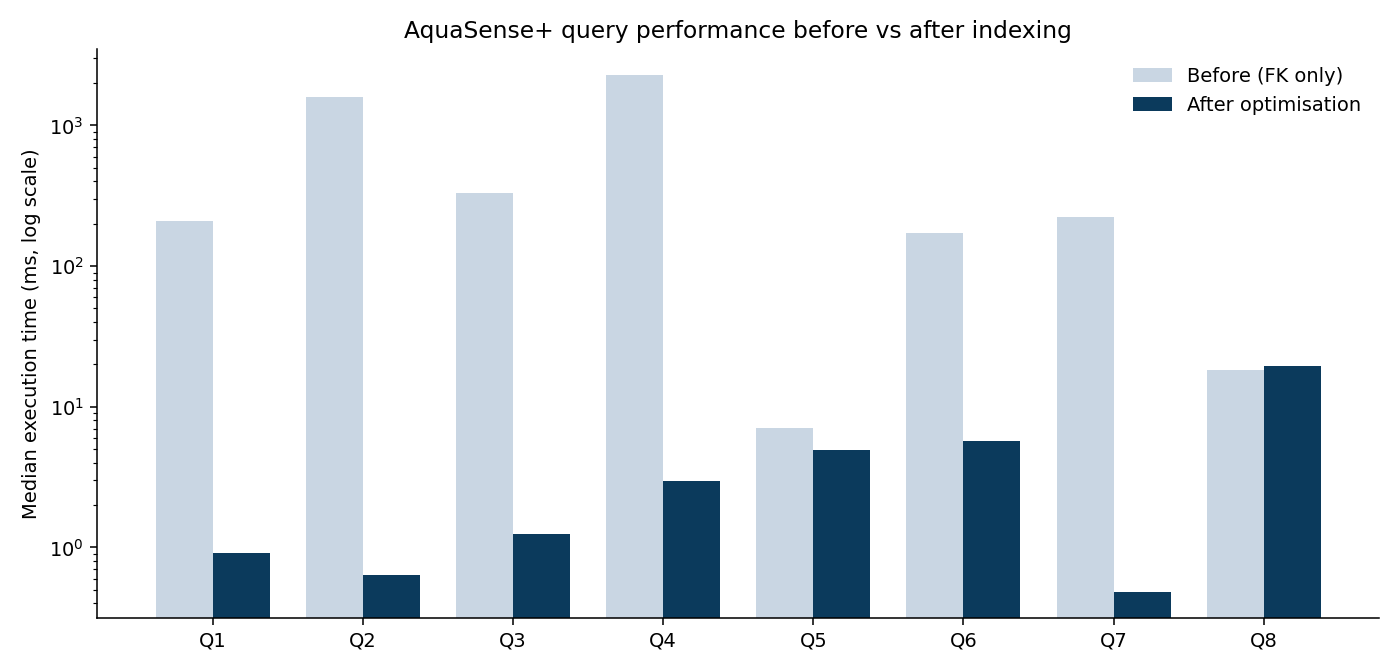

In [24]:
Image("performance_chart.png")

## 6. Execution plans: Q4 before and after indexing
Before: look for **Seq Scan on feeding_log**. After: look for **Index Only Scan using ix_feeding_batch_cov** and **Heap Fetches: 0**.

In [25]:
print(open("plans/Q4_before.txt", encoding="utf-8").read())

-- Q4: Batch report: feed used, harvest weight and FCR for every closed batch on one farm
-- phase: before

SELECT b.batch_id, cu.unit_code, b.stocked_on, b.closed_on,
       fl.feed_kg,
       h.harvest_kg,
       ROUND(fl.feed_kg / NULLIF(h.harvest_kg - b.initial_count * b.initial_avg_weight_g / 1000, 0), 2) AS fcr
FROM aqua.stock_batch b
JOIN aqua.culture_unit cu ON cu.unit_id = b.unit_id
JOIN LATERAL (SELECT SUM(qty_kg) AS feed_kg   FROM aqua.feeding_log fl WHERE fl.batch_id = b.batch_id) fl ON TRUE
JOIN LATERAL (SELECT SUM(total_weight_kg) AS harvest_kg FROM aqua.harvest h WHERE h.batch_id = b.batch_id) h ON TRUE
WHERE cu.farm_id = 64 AND b.status = 'harvested'
ORDER BY b.stocked_on

Sort  (cost=286193.56..286193.63 rows=27 width=116) (actual time=1844.760..1844.764 rows=26 loops=1)
  Sort Key: b.stocked_on
  Sort Method: quicksort  Memory: 26kB
  Buffers: shared hit=6394 read=103766
  ->  Nested Loop  (cost=10608.37..286192.92 rows=27 width=116) (actual time=77.754..1844.686 rows

In [26]:
print(open("plans/Q4_after.txt", encoding="utf-8").read())

-- Q4: Batch report: feed used, harvest weight and FCR for every closed batch on one farm
-- phase: after

SELECT b.batch_id, cu.unit_code, b.stocked_on, b.closed_on,
       fl.feed_kg,
       h.harvest_kg,
       ROUND(fl.feed_kg / NULLIF(h.harvest_kg - b.initial_count * b.initial_avg_weight_g / 1000, 0), 2) AS fcr
FROM aqua.stock_batch b
JOIN aqua.culture_unit cu ON cu.unit_id = b.unit_id
JOIN LATERAL (SELECT SUM(qty_kg) AS feed_kg   FROM aqua.feeding_log fl WHERE fl.batch_id = b.batch_id) fl ON TRUE
JOIN LATERAL (SELECT SUM(total_weight_kg) AS harvest_kg FROM aqua.harvest h WHERE h.batch_id = b.batch_id) h ON TRUE
WHERE cu.farm_id = 64 AND b.status = 'harvested'
ORDER BY b.stocked_on

Sort  (cost=637.80..637.87 rows=27 width=116) (actual time=2.959..2.967 rows=26 loops=1)
  Sort Key: b.stocked_on
  Sort Method: quicksort  Memory: 26kB
  Buffers: shared hit=222
  ->  Nested Loop  (cost=27.96..637.16 rows=27 width=116) (actual time=0.204..2.935 rows=26 loops=1)
        Buffers: shared

## 7. Sargability: Q6 vs Q7 (same question, same index)
Q6 wraps the column in `date(...)`, so the date becomes a **Filter** with *Rows Removed by Filter*. Q7 uses a range, so both columns appear in **Index Cond**. Compare the `Buffers` lines.

In [27]:
for q in ("Q6", "Q7"):
    print("=" * 80)
    print(open(f"plans/{q}_after.txt", encoding="utf-8").read())

-- Q6: Sargability: all readings on 1 Oct 2026 for one pond (BAD form — function on the column)
-- phase: after

SELECT count(*), ROUND(AVG(dissolved_oxygen_mgl), 2) AS avg_do
FROM aqua.water_quality_reading
WHERE unit_id = 316
  AND date(recorded_at AT TIME ZONE 'Africa/Lagos') = DATE '2026-10-01'

Aggregate  (cost=1374.60..1374.61 rows=1 width=40) (actual time=5.405..5.405 rows=1 loops=1)
  Buffers: shared hit=59
  ->  Index Scan using ix_wqr_unit_time on water_quality_reading  (cost=0.42..1374.58 rows=4 width=6) (actual time=0.612..5.385 rows=12 loops=1)
        Index Cond: (unit_id = 316)
        Filter: (date((recorded_at AT TIME ZONE 'Africa/Lagos'::text)) = '2026-10-01'::date)
        Rows Removed by Filter: 3669
        Buffers: shared hit=59
Planning Time: 0.174 ms
Execution Time: 5.450 ms

-- Q7: Sargability: same question rewritten as a range (GOOD form — index-friendly)
-- phase: after

SELECT count(*), ROUND(AVG(dissolved_oxygen_mgl), 2) AS avg_do
FROM aqua.water_quality_r

## 8. Q8: the materialized view

In [28]:
print(open("plans/Q8_materialized_view.txt", encoding="utf-8").read())

SELECT * FROM aqua.mv_state_monthly_sales WHERE month >= DATE '2026-01-01' ORDER BY state_code, month

Sort  (cost=8.54..8.77 rows=93 width=80) (actual time=0.078..0.084 rows=136 loops=1)
  Sort Key: state_code, month
  Sort Method: quicksort  Memory: 31kB
  Buffers: shared hit=2
  ->  Seq Scan on mv_state_monthly_sales  (cost=0.00..5.50 rows=93 width=80) (actual time=0.014..0.043 rows=136 loops=1)
        Filter: (month >= '2026-01-01'::date)
        Rows Removed by Filter: 144
        Buffers: shared hit=2
Planning Time: 0.058 ms
Execution Time: 0.102 ms

-- REFRESH CONCURRENTLY took 100.6 ms



## 9. Write cost: what the indexes cost on 100,000 inserts
Both inserts are rolled back, so the database is not changed. Compare the two `Time:` lines after each `INSERT 0 100000`.

In [29]:
!psql -f write_cost_test.sql > results/write_cost_output.txt 2>&1
lines = open("results/write_cost_output.txt", encoding="utf-8").read().splitlines()
for i, l in enumerate(lines):
    if "===" in l:
        print(l.strip("= "))
    if l.startswith("INSERT"):
        print("   100,000 inserts took", lines[i + 1].replace("Time:", "").strip())

WITH ix_wqr_unit_time + ix_wqr_low_oxygen
   100,000 inserts took 2528.081 ms (00:02.528)
WITHOUT the two indexes (dropped inside the transaction)
   100,000 inserts took 2046.922 ms (00:02.047)
